# Kex transfer from OSSL to Fukushima

> Pretrain a CNN on OSSL exchangeable potassium (Kex), then compare zero-shot prediction, fine-tuning and Fukushima-only training on the Fukushima test set

In [ ]:
import copy
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score
from fastai.layers import NormType
from fastai.callback.schedule import *
from fastai.torch_core import set_seed
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspectfm.preprocessing import SNV, SavitzkyGolay
from soilspecdl.all import *
from ossl_fuku_transfer.data import *

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`. The outputs come from a local run on an Apple silicon GPU (MPS). This is a single run with one seed. The notebook does not measure how much the results vary between runs.

## Data

OSSL MIR spectra on the shared grid, with Kex in cmolc/kg. Kex is skewed, so the models predict `log1p(Kex)`:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('k.ext_usda.a725_cmolc.kg')
yo = np.log1p(yo.ravel())
Xo.shape

(57674, 1675)

The Fukushima spectra, with Kex converted from mg K₂O per 100 g to cmolc/kg. The test set is the Cs137 study's test set:

In [ ]:
#| fukudata
fuku = load_fuku()
fuku.source = fuku.source.assign(kex=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('kex')
yf = np.log1p(yf.ravel())
_, test_ids = cs137_split()
is_test = np.isin(idf, test_ids)
Xf.shape, int(is_test.sum())

((1388, 1675), 341)

## Preprocessing

Two preprocessings, each fitted on OSSL and applied to Fukushima: SNV, and SNV followed by a Savitzky-Golay first derivative, as in the soilspecdl quick start. In both, `BatchSNV` standardizes each spectrum in a batch. After SNV it changes almost nothing. After the derivative it brings the spectra back to unit scale:

In [ ]:
#| fukudata
pipes = {'snv': Pipeline([('snv', SNV())]),
         'snv_d1': Pipeline([('snv', SNV()), ('deriv', SavitzkyGolay(deriv=1))])}
data = {k: (p.fit_transform(Xo), p.transform(Xf)) for k, p in pipes.items()}

## Pretraining on OSSL

The CNN of Albinet et al. (2022), trained as in the soilspecdl quick start: a random 90/10 split of OSSL into training and validation, and 20 epochs of one-cycle training. `pretrain` saves the weights and the training history in `data/models/ossl-fuku-transfer/`. Later runs load them instead of training again. The table shows the last epoch of each pretraining, with the R² of `log1p(Kex)` on the OSSL validation set:

In [ ]:
#| fukudata
model_dir = data_path()/'models'/'ossl-fuku-transfer'
model_dir.mkdir(parents=True, exist_ok=True)

def new_model(): return SpectralCNN(nfs=(16, 32, 64, 128, 256), pool_sz=3, norm_type=NormType.Batch)

def pretrain(name, X):
    fn, model = model_dir/f'ossl_kex_{name}.pth', new_model()
    if not fn.exists():
        set_seed(42)
        dls, _ = get_spectral_dls(X, yo, shared_wns, splitter=get_splitter(0.9, 0.1), batch_tfms=[BatchSNV()])
        learn = spectral_learner(dls, model)
        with learn.no_bar(), learn.no_logging(): learn.fit_one_cycle(20, lr_max=1e-3)
        torch.save(model.state_dict(), fn)
        hist = pd.DataFrame(learn.recorder.values, columns=learn.recorder.metric_names[1:-1])
        hist.to_csv(fn.with_suffix('.csv'), index_label='epoch')
    model.load_state_dict(torch.load(fn, map_location='cpu'))
    return model

In [ ]:
#| fukudata
pretrained = {k: pretrain(k, Xo_k) for k, (Xo_k, _) in data.items()}
pd.DataFrame({k: pd.read_csv(model_dir/f'ossl_kex_{k}.csv', index_col='epoch').iloc[-1] for k in data}).T.round(3)

,train_loss,valid_loss,r2_score
snv,0.032,0.037,0.744
snv_d1,0.023,0.030,0.794


## Fukushima models

`fuku_dls` puts all Fukushima spectra in one `DataLoaders`. A random 10% of the training samples is the validation set, and the test set is the Cs137 test set. `test_preds` predicts the test set:

In [ ]:
#| fukudata
test_idx = np.flatnonzero(is_test)

def fuku_dls(X, valid_pct=0.1, seed=42):
    train_idx = np.flatnonzero(~is_test)
    np.random.RandomState(seed).shuffle(train_idx)
    n_valid = int(len(train_idx) * valid_pct)
    split = lambda X, y: (train_idx[n_valid:], train_idx[:n_valid], test_idx)
    return get_spectral_dls(X, yf, shared_wns, splitter=split, batch_tfms=[BatchSNV()])[0]

def test_preds(learn):
    with learn.no_bar(): preds, _ = learn.get_preds(dl=learn.dls.test_dl(test_idx.tolist(), with_labels=True))
    return preds.numpy().ravel()

Three models for each preprocessing. Zero-shot uses the OSSL model as it is. Fine-tuned trains the head for one epoch with the backbone frozen, then the whole model for 20 epochs, with a lower learning rate for the backbone (fastai's `fine_tune`). Fukushima-only trains the same CNN from random weights for 21 epochs:

In [ ]:
#| fukudata
def run(name):
    dls, res = fuku_dls(data[name][1]), {}
    learn = spectral_learner(dls, copy.deepcopy(pretrained[name]))
    res['zero-shot'] = test_preds(learn)
    set_seed(42)
    learn = spectral_learner(dls, copy.deepcopy(pretrained[name]))
    with learn.no_bar(), learn.no_logging(): learn.fine_tune(20, base_lr=1e-3)
    res['fine-tuned'] = test_preds(learn)
    set_seed(42)
    learn = spectral_learner(dls, new_model())
    with learn.no_bar(), learn.no_logging(): learn.fit_one_cycle(21, lr_max=1e-3)
    res['Fukushima only'] = test_preds(learn)
    return res

preds = {k: run(k) for k in pipes}

## Results

R² and Pearson correlation `r` of `log1p(Kex)`, and the root mean squared error and mean error (bias) of Kex in cmolc/kg, on the 341 test samples that have a Kex value. A zero-shot model with a large bias can still rank the samples well, which shows as a high `r` with a low R²:

In [ ]:
#| fukudata
yt = yf[is_test]
def scores(p):
    err = np.expm1(p) - np.expm1(yt)
    return {'R² log1p': r2_score(yt, p), 'r log1p': np.corrcoef(yt, p)[0, 1], 'RMSE': np.sqrt((err**2).mean()), 'bias': err.mean()}
results = pd.DataFrame({(k, m): scores(p) for k, d in preds.items() for m, p in d.items()}).T
results.round(3)

R² log1p  r log1p   RMSE   bias
snv    zero-shot         -0.647    0.013  0.508 -0.100
       fine-tuned         0.080    0.287  0.393 -0.047
       Fukushima only     0.171    0.443  0.373 -0.035
snv_d1 zero-shot         -0.820    0.126  0.537  0.285
       fine-tuned         0.092    0.319  0.389 -0.060
       Fukushima only     0.330    0.580  0.330 -0.028

For scale, the standard deviation of the test Kex values, in cmolc/kg:

In [ ]:
#| fukudata
round(float(np.expm1(yt).std()), 3)

0.406

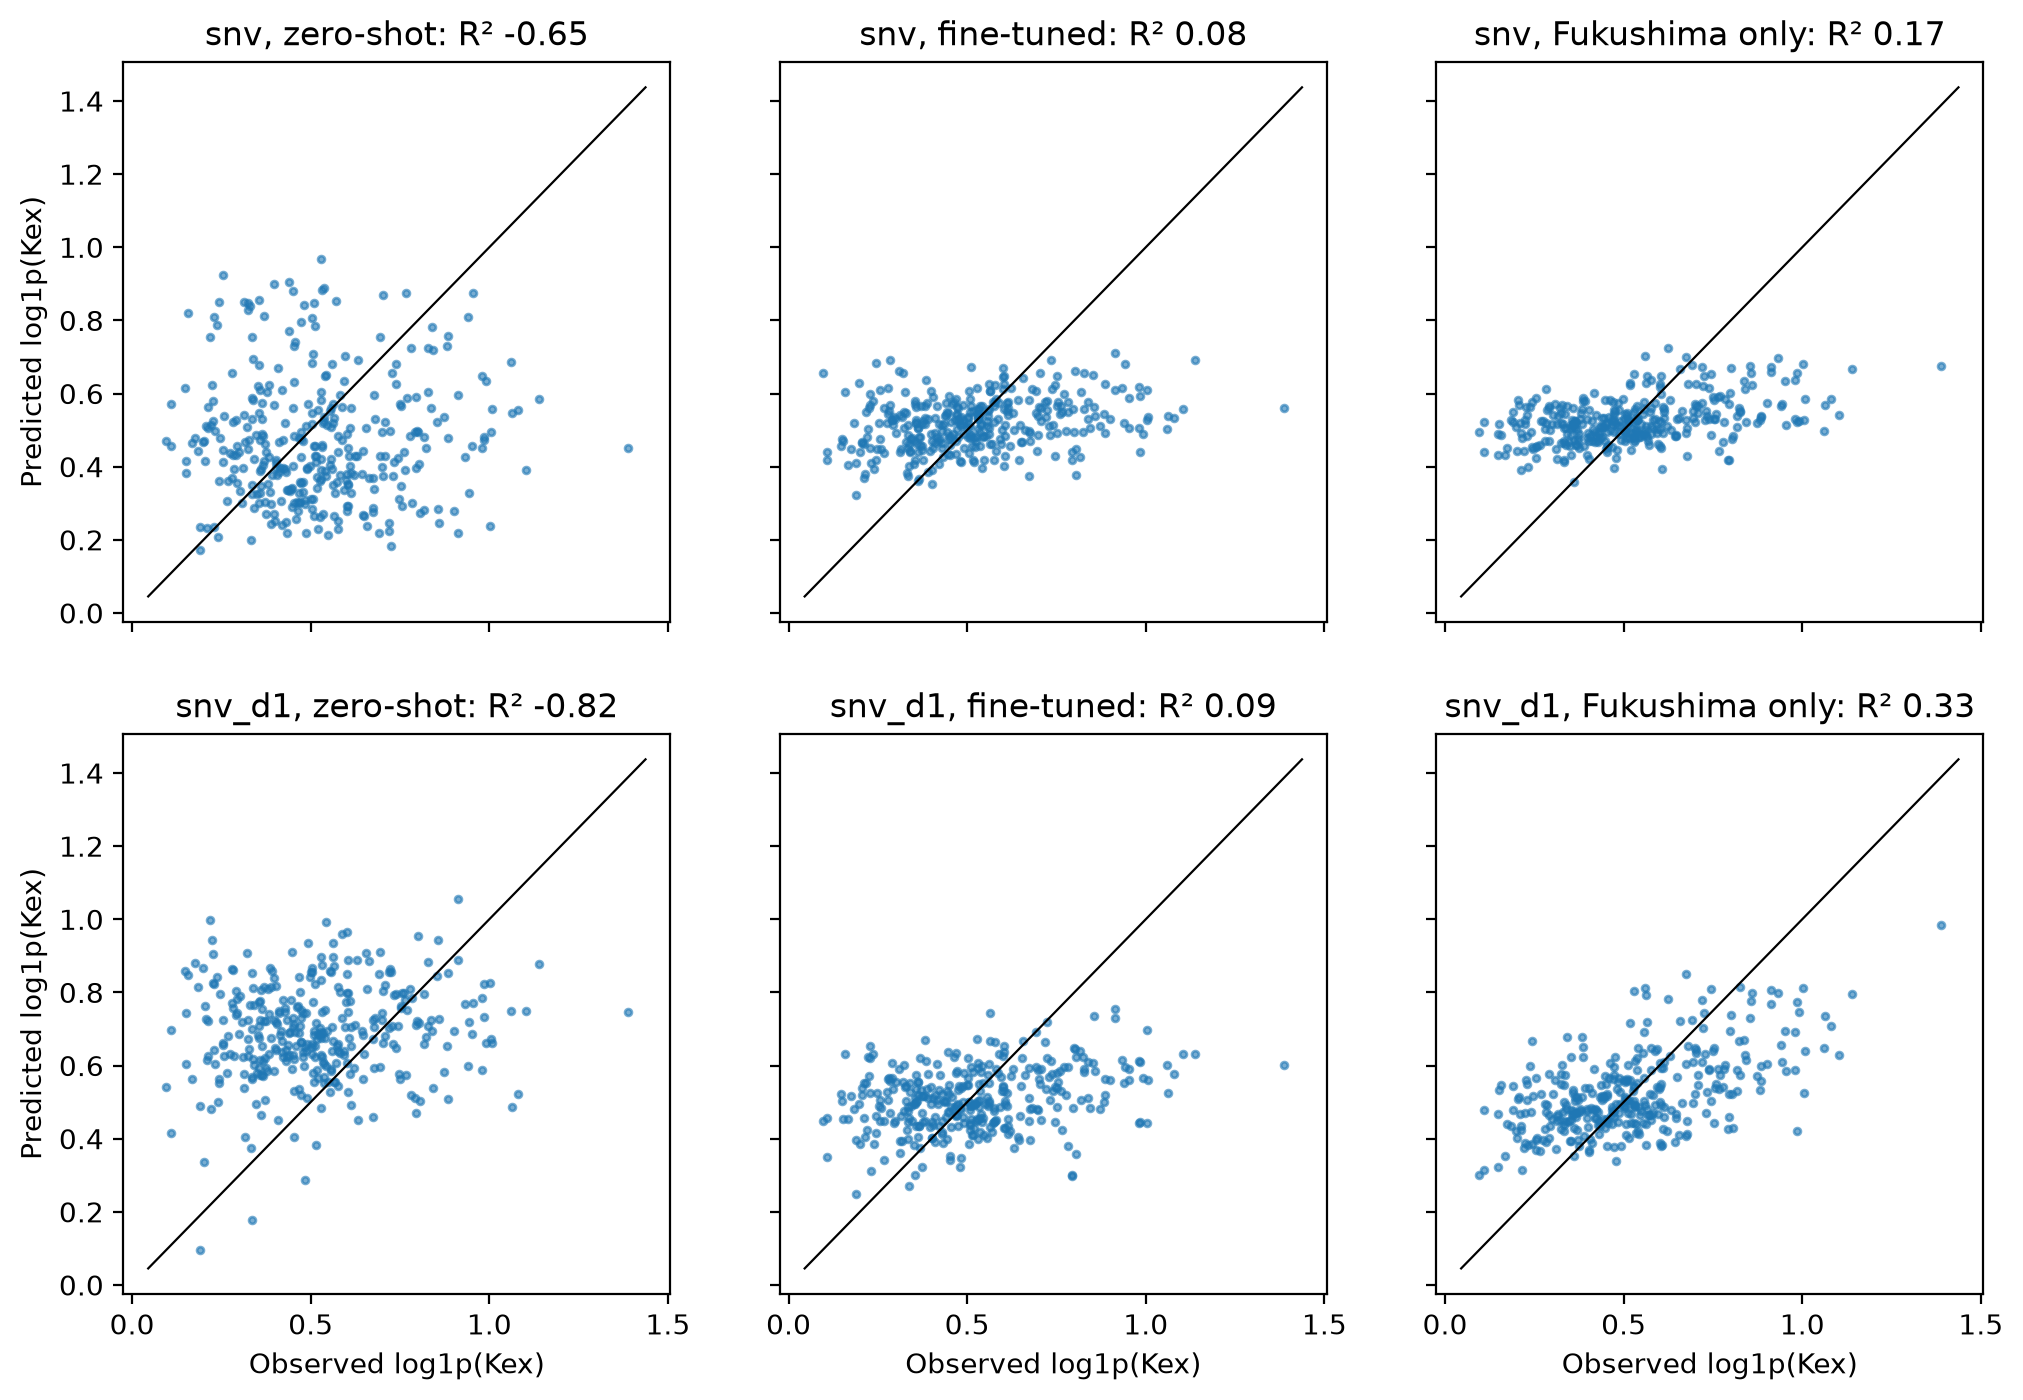

In [ ]:
#| fukudata
fig, axs = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)
lims = [yt.min() - 0.05, yt.max() + 0.05]
for row, (k, d) in zip(axs, preds.items()):
    for ax, (m, p) in zip(row, d.items()):
        ax.scatter(yt, p, s=6, alpha=0.6)
        ax.plot(lims, lims, c='k', lw=0.8)
        ax.set_title(f'{k}, {m}: R² {r2_score(yt, p):.2f}')
for ax in axs[-1]: ax.set_xlabel('Observed log1p(Kex)')
for ax in axs[:, 0]: ax.set_ylabel('Predicted log1p(Kex)')

## Error analysis

Mean absolute error of `log1p(Kex)` of the fine-tuned models, by soil type, year and measurement batch, with the number of test samples in each group:

In [ ]:
#| fukudata
props = fuku.source.loc[idf[is_test]]
groups = {'soil type': props['Soil_type_describe'].to_numpy(), 'year': props['year'].astype(int).to_numpy(), 'batch': sample_batches(idf[is_test])}
def by_group(g):
    df = pd.DataFrame({k: np.abs(d['fine-tuned'] - yt) for k, d in preds.items()}).assign(n=1)
    return df.groupby(groups[g]).agg({**{k: 'mean' for k in preds}, 'n': 'sum'}).round(3)
by_group('soil type')

,snv,snv_d1,n
Andosols,0.165,0.173,44
Forest soil,0.183,0.169,27
Glay soil,0.149,0.198,6
Lowland soil,0.152,0.153,244
Peat soil,0.214,0.230,14
Red yellow soil,0.196,0.201,6


In [ ]:
#| fukudata
by_group('year')

,snv,snv_d1,n
2013,0.191,0.198,34
2014,0.174,0.176,53
2015,0.121,0.131,48
2016,0.147,0.136,58
2017,0.148,0.148,37
2018,0.175,0.181,46
2019,0.157,0.162,49
2020,0.193,0.193,16


In [ ]:
#| fukudata
by_group('batch')

,snv,snv_d1,n
batch 1,0.175,0.170,110
batch 2,0.152,0.157,231


## Checks

The OSSL validation R² covers OSSL's whole Kex range. Fukushima's Kex covers a narrower band. The pretrained models are scored again on their OSSL validation samples, first all of them, then those within the 5th to 95th percentile of Fukushima Kex:

In [ ]:
#| fukudata
lo, hi = np.quantile(yf, [0.05, 0.95])
def ossl_valid(name):
    dls, _ = get_spectral_dls(data[name][0], yo, shared_wns, splitter=get_splitter(0.9, 0.1), batch_tfms=[BatchSNV()])
    learn = spectral_learner(dls, copy.deepcopy(pretrained[name]))
    with learn.no_bar(): p, t = learn.get_preds(ds_idx=1)
    p, t = p.numpy().ravel(), t.numpy().ravel()
    m = (t >= lo) & (t <= hi)
    return {'n all': len(t), 'R² all': r2_score(t, p), 'r all': np.corrcoef(t, p)[0, 1],
            'n in range': int(m.sum()), 'R² in range': r2_score(t[m], p[m]), 'r in range': np.corrcoef(t[m], p[m])[0, 1]}
np.expm1([lo, hi]).round(2), pd.DataFrame({k: ossl_valid(k) for k in data}).T.round(3)

(array([0.22, 1.63]),
          n all  R² all  r all  n in range  R² in range  r in range
 snv     5767.0   0.744  0.863      3227.0        0.259       0.670
 snv_d1  5767.0   0.794  0.892      3227.0        0.378       0.725)

A spectral model predicts Kex partly through the soil properties that Kex varies with. Spearman correlations of Kex with CEC and with total carbon, in OSSL, in OSSL samples within Fukushima's Kex range, in OSSL Andisols, and in Fukushima:

In [ ]:
#| fukudata
ocols = {'k.ext_usda.a725_cmolc.kg': 'Kex', 'cec_usda.a723_cmolc.kg': 'CEC', 'c.tot_usda.a622_w.pct': 'C'}
op_ = om.source[list(ocols)].rename(columns=ocols).reindex(om.sample_ids)
fp = fuku.source.loc[fuku.sample_ids, ['kex', 'soil_CEC', 'soil_C']].set_axis(['Kex', 'CEC', 'C'], axis=1)
in_rng = op_.Kex.between(*np.expm1([lo, hi]))
andisol = om.source['pedon.taxa_usda_txt'].reindex(om.sample_ids).astype('string').str.contains(r'[a-z]ands?\b|andepts?\b', na=False)
def corrs(df): return {'Kex–CEC': df.Kex.corr(df.CEC, method='spearman'), 'Kex–C': df.Kex.corr(df.C, method='spearman'), 'CEC–C': df.CEC.corr(df.C, method='spearman'), 'n': len(df.dropna())}
pd.DataFrame({'OSSL': corrs(op_), 'OSSL in Fukushima range': corrs(op_[in_rng]), 'OSSL Andisols': corrs(op_[andisol.to_numpy()]), 'Fukushima': corrs(fp)}).T.round(2)

,Kex–CEC,Kex–C,CEC–C,n
OSSL,0.60,0.36,0.56,53360.0
OSSL in Fukushima range,0.33,0.18,0.39,30494.0
OSSL Andisols,0.47,0.36,0.67,1444.0
Fukushima,0.29,0.03,0.41,1385.0


## Findings

These findings come from one run. Two runs of this notebook with the same seed gave different SNV results: an OSSL validation R² of 0.757 and then 0.744, and a zero-shot bias of -0.26 and then -0.10 cmolc/kg. The derivative results were the same in both runs. Training on MPS is therefore not fully deterministic, and the comparisons need repeating over several seeds.

Pretraining works. The OSSL validation R² of `log1p(Kex)` is 0.74 with SNV and 0.79 with SNV and the first derivative.

The OSSL models do not transfer to Fukushima without training. Their zero-shot R² is negative, and their correlation with the observed values is 0.01 with SNV and 0.13 with the derivative. The narrower Kex range of Fukushima does not explain this. On their own OSSL validation samples within Fukushima's Kex range (0.22 to 1.63 cmolc/kg), the same models keep a correlation of 0.67 and 0.73. The zero-shot failure therefore comes from the Fukushima spectra: the instrument, the sample preparation, or a soil population that OSSL does not cover.

The relation between Kex and the soil does not explain it either. The Spearman correlation of Kex with CEC is 0.29 in Fukushima and 0.33 in OSSL samples within the same Kex range. The correlation of Kex with total carbon is weaker in Fukushima (0.03 against 0.18).

Fukushima Kex is about as predictable from Fukushima spectra as OSSL Kex is from OSSL spectra in the same range. The CNN trained on Fukushima only, with the derivative, reaches an R² of 0.33 and a correlation of 0.58 on the test set. The OSSL model reaches 0.38 and 0.73 on OSSL samples in that range.

Fine-tuning the OSSL models on the Fukushima training samples gives an R² of 0.08 to 0.09, below the Fukushima-only models (0.17 with SNV and 0.33 with the derivative). With this fine-tuning schedule, the OSSL pretraining does not help.

The errors of the fine-tuned models vary little by soil type, year or measurement batch. Peat soils have the largest mean absolute error, but the smallest groups have 6 to 14 test samples.